## import Libraries

In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

## Download Dataset Form The Kaggle

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shivasingh4945/student-social-media-and-mental-health-impact")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'student-social-media-and-mental-health-impact' dataset.
Path to dataset files: /kaggle/input/student-social-media-and-mental-health-impact


## Load Database

In [3]:
df = pd.read_csv('/kaggle/input/student-social-media-and-mental-health-impact/Student Social Media And Mental Health Impact.csv')

In [4]:
## Read Data To head
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [5]:
## Show The Data Columns, Datatype , Null etc...
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [6]:
## check the null values
df.isnull().sum()

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


In [7]:
# check the duplicated value's
df.duplicated().sum()

np.int64(2)

In [8]:
## describe
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


## EDA

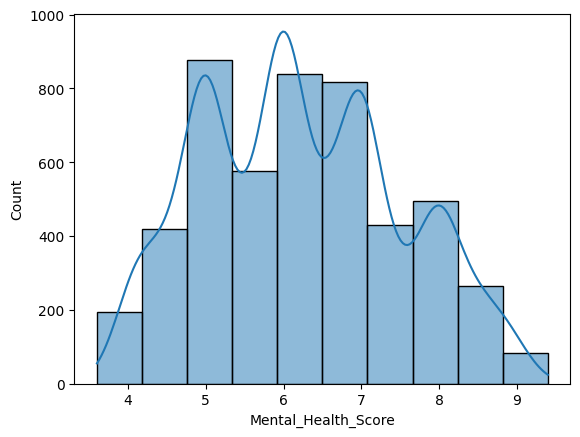

In [9]:
## check data skewness
sns.histplot(df,x='Mental_Health_Score',kde=True,bins=10)
plt.show()

<Axes: >

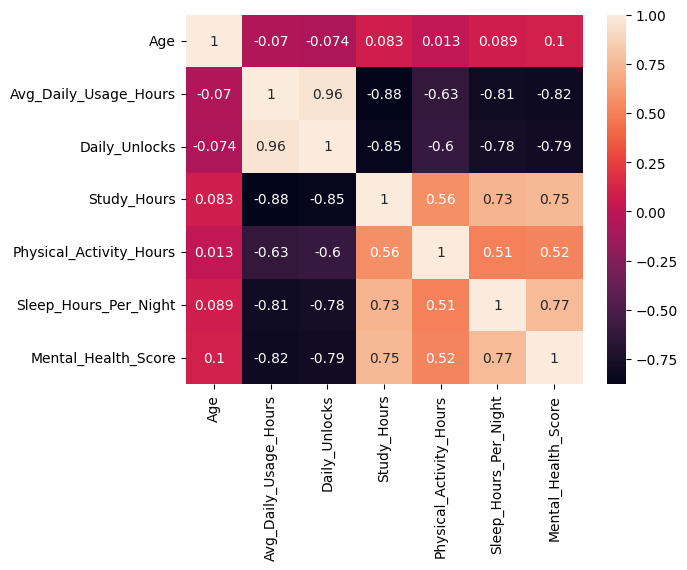

In [10]:
## check the corelation
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [11]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [12]:
df['Stress_Level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

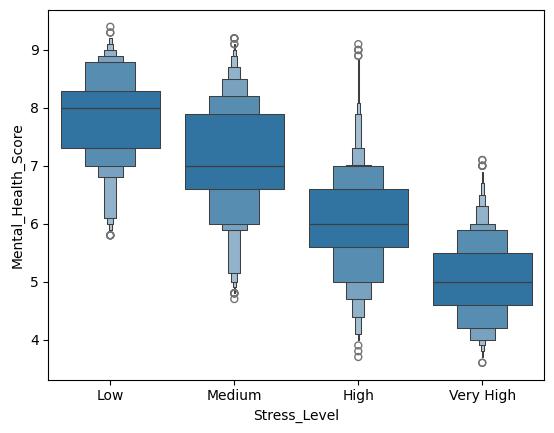

In [13]:
## Stress_Level vs Mental_Health_Score

order = ['Low','Medium', 'High','Very High']
sns.boxenplot(df,x='Stress_Level',y='Mental_Health_Score',order=order)

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

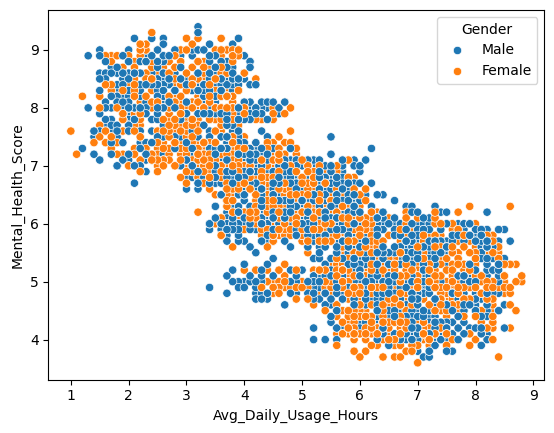

In [14]:
## Avg_Daily_Usage_Hours vs Mental_Health_Score
## show the nagative Corelation
sns.scatterplot(df,x='Avg_Daily_Usage_Hours',y='Mental_Health_Score',hue='Gender')

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

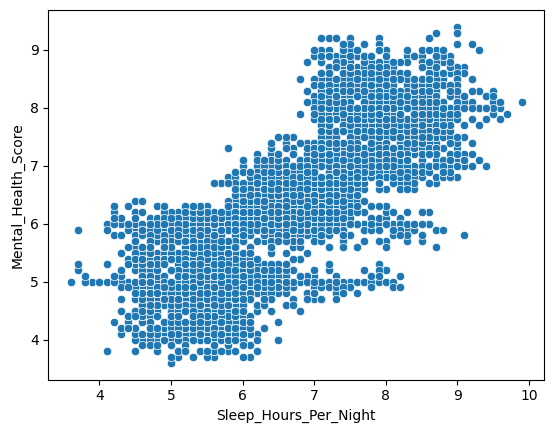

In [15]:
##  Sleep_Hours_Per_Night vs Mental_Health_Score
sns.scatterplot(df,x='Sleep_Hours_Per_Night',y='Mental_Health_Score')

In [16]:

df['Most_Used_Platform'].value_counts().index

Index(['Instagram', 'TikTok', 'Facebook', 'LinkedIn', 'YouTube', 'Twitter',
       'Snapchat', 'WhatsApp', 'LINE', 'VKontakte', 'KakaoTalk', 'WeChat'],
      dtype='object', name='Most_Used_Platform')

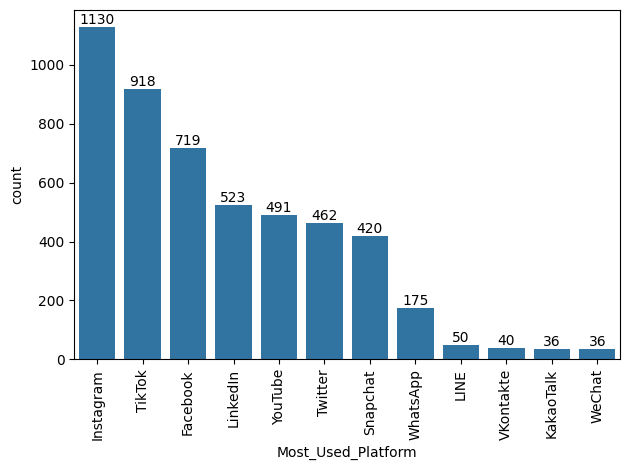

In [17]:
## find the most used platform
ax = sns.countplot(df,x='Most_Used_Platform',order=df['Most_Used_Platform'].value_counts().index)

for i in ax.containers:
  ax.bar_label(i)

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [18]:
## checking outliers
num_feature = df.select_dtypes(include='number')
num_feature.head()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
0,21,4.0,134,4.5,2.2,6.7,6.8
1,23,1.6,73,7.0,2.4,8.6,7.6
2,22,4.6,166,4.0,1.8,6.7,7.0
3,18,7.0,220,1.0,1.7,5.4,5.3
4,24,7.5,237,1.0,1.1,5.0,4.4


In [19]:
Q1 = num_feature.quantile(0.25)
Q3 = num_feature.quantile(0.75)
IQR = Q3 - Q1

# lower bound
lb = Q1 - 1.5 * IQR
# upper bound
up = Q3 + 1.5 * IQR

## outliers
outliers = (num_feature < lb) | (num_feature > up)
print(outliers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


## Data cleaning

In [20]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [21]:
## drop the duplicates value
df = df.drop_duplicates()

In [22]:
## remove the nagative value's or unrealitstic values
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)

In [23]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


## Check the skewness

| Skewness |	Interpretation |
|--------- | ----------------|
| Near 0	 | Approximately symmetrical |
| Greater than +0.5 |	Noticeable right skew |
| Less than -0.5 |	Noticeable left skew |
| Greater than +1 or less than -1 |	Strong skew|

In [24]:
num_cols = df.select_dtypes(include='number')
num_cols.skew()
# near to 0 -> centralized data
# nagative -> left skewed
# postive -> right skewed


,0
Age,0.155008
Avg_Daily_Usage_Hours,0.005575
Daily_Unlocks,0.002309
Study_Hours,0.436125
Physical_Activity_Hours,0.053288
Sleep_Hours_Per_Night,0.123919
Mental_Health_Score,0.207086


# Feature Engineering

In [25]:
top_country = df['Country'].value_counts().index[:10].tolist()

In [26]:
def grouped_coundtries(country):
  if country in top_country:
    return country
  else:
    return 'Other'

In [27]:
df['Grouped_country']= df['Country'].apply(grouped_coundtries)

In [28]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Grouped_country
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8,Other
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6,Other
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0,Canada
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3,Other
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4,Other


In [29]:
df['Grouped_country'].value_counts()

,count
Grouped_country,
Other,3231
India,389
USA,354
Canada,230
Australia,198
UK,185
Germany,136
Mexico,94
Turkey,94


In [30]:
from sklearn.model_selection import train_test_split

skewed_col         = ['Study_Hours']
other_numeric_cols = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks","Physical_Activity_Hours",
                      "Sleep_Hours_Per_Night"]
ordinal_col        = ['Stress_Level']
normal_col         = ["Gender", "Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "Grouped_country"]

feature_col = skewed_col + other_numeric_cols + ordinal_col + normal_col
X = df[feature_col]
y = df['Mental_Health_Score']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42)

## pipeline create

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder

## skewed feature
skew_pipeline = Pipeline(
    steps=[
        ('log_transform',FunctionTransformer(np.log1p)),
        ('scale',StandardScaler())
    ]
)

## numeric feature
plain_numeric_pipeline = Pipeline(
    steps=[
        ('scale',StandardScaler())
    ]
)

## ordinal feature
ordinal_pipeline = Pipeline(
    steps=[
        ('ordinal_encoder',OrdinalEncoder(
            categories=[['Low', 'Medium', 'High', 'Very High']]
        ))
    ]
)


## nominal feature
nominal_pipeline = Pipeline(
    steps=[
        ('onehot_encoder',OneHotEncoder(drop='first',handle_unknown='ignore'))
    ]
)

In [32]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('skew_pipeline',skew_pipeline,skewed_col),
        ('plain_numeric_pipeline',plain_numeric_pipeline,other_numeric_cols),
        ('ordinal_pipeline',ordinal_pipeline,ordinal_col),
        ('nominal_pipeline',nominal_pipeline,normal_col)
    ]
)

In [33]:
## create base model

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

## create pipeline

lr_pipeline = Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('model',LinearRegression())
    ]
)

lr_pipeline.fit(X_train,y_train)
lr_test_pred = lr_pipeline.predict(X_test)
lr_train_pred = lr_pipeline.predict(X_train)

# testing
print("MSE testing :",mean_squared_error(y_test,lr_test_pred))
print("MAE testing:",mean_absolute_error(y_test,lr_test_pred))
print("R2 Score testing:",r2_score(y_test,lr_test_pred))

# training
print("MSE training:",mean_squared_error(y_train,lr_train_pred))
print("MAE training:",mean_absolute_error(y_train,lr_train_pred))
print("R2 Score training:",r2_score(y_train,lr_train_pred))

MSE testing : 0.45701905273488
MAE testing: 0.5361775634720183
R2 Score testing: 0.739794461743302
MSE training: 0.4367848338582864
MAE training: 0.5189846926901907
R2 Score training: 0.7236771199387539


In [34]:
## defualt model create
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('model',RandomForestRegressor(random_state=42))
    ]
)

rf_pipeline.fit(X_train,y_train)
rf_test_pred = rf_pipeline.predict(X_test)
rf_train_pred = rf_pipeline.predict(X_train)

# testing
print("MSE testing :",mean_squared_error(y_test,rf_test_pred))
print("MAE testing:",mean_absolute_error(y_test,rf_test_pred))
print("R2 Score testing:",r2_score(y_test,rf_test_pred))

# training
print("MSE training:",mean_squared_error(y_train,rf_train_pred))
print("MAE training:",mean_absolute_error(y_train,rf_train_pred))
print("R2 Score training:",r2_score(y_train,rf_train_pred))

MSE testing : 0.21807397863333328
MAE testing: 0.3500088666666668
R2 Score testing: 0.8758387497184198
MSE training: 0.030649814451114962
MAE training: 0.12694576901086344
R2 Score training: 0.9806100295936038


## Hyperparameter Tuning the Random Forest

In [35]:
from sklearn.model_selection import RandomizedSearchCV

# Prefix the parameter keys with 'model__' to target the RandomForestRegressor step
param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [5, 10, 15],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

In [36]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    scoring='r2',
    cv=5,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)
print("Best parameters:", random_search.best_params_)
print("Best CV R2 score:", random_search.best_score_)

Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_depth': 15}
Best CV R2 score: 0.831597194738635


In [37]:
rf_best_pipeline = random_search.best_estimator_
y_test_pred = rf_best_pipeline.predict(X_test)
y_train_pred = rf_best_pipeline.predict(X_train)


# testing
print("MSE testing :",mean_squared_error(y_test,y_test_pred))
print("MAE testing:",mean_absolute_error(y_test,y_test_pred))
print("R2 Score testing:",r2_score(y_test,y_test_pred))

# training
print("MSE training:",mean_squared_error(y_train,y_train_pred))
print("MAE training:",mean_absolute_error(y_train,y_train_pred))
print("R2 Score training:",r2_score(y_train,y_train_pred))

MSE testing : 0.2520151595492579
MAE testing: 0.3832488592483886
R2 Score testing: 0.8565142090970915
MSE training: 0.10251380847308503
MAE training: 0.23940077096104626
R2 Score training: 0.935146761958039


## Check The Model Evaluation For The All Model

In [38]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Calculate metrics for Linear Regression
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_test_pred))
lr_mae = mean_absolute_error(y_test, lr_test_pred)
lr_r2_testing = r2_score(y_test, lr_test_pred)
lr_r2_training = r2_score(y_train, lr_train_pred)

# Calculate metrics for default Random Forest
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_test_pred))
rf_mae = mean_absolute_error(y_test, rf_test_pred)
rf_r2_testing = r2_score(y_test, rf_test_pred)
rf_r2_training = r2_score(y_train, rf_train_pred)

# Calculate metrics for tuned Random Forest
rf_tuned_preds          = random_search.best_estimator_.predict(X_test)
rf_tuned_rmse           = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_training       = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae            = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2             = r2_score(y_test, rf_tuned_preds)

# Create a DataFrame to consolidate results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_r2_testing, rf_r2_testing, rf_tuned_r2],
    'Training R2': [lr_r2_training, rf_r2_training, r2_tuned_training],
    'MAE': [lr_mae, rf_mae, rf_tuned_mae],
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)

                     Model        R2  Training R2       MAE      RMSE
0        Linear Regression  0.739794     0.723677  0.536178  0.676032
1  Random Forest (default)  0.875839     0.980610  0.350009  0.466984
2    Random Forest (tuned)  0.856514     0.935147  0.383249  0.502011


## save the model

In [39]:
import joblib
joblib.dump(rf_pipeline,'Mental_Health_Model.pkl')

['Mental_Health_Model.pkl']